# 03 — Modeling: Logistic Regression and Comparison Models

**AAI-500 Final Team Project, Group 02 — Who Is at Risk of Credit Card Default?**

Names: Abhineet Sood, Ravi Kanth Vuddagiri
Date: October 19, 2026

Our main model is a **logistic regression**. It gives each client a probability of default, and its
coefficients can be explained as odds ratios with P-values and confidence intervals. We then compare it
with three other models to see how much accuracy (if any) we give up by using a model we can explain.

Plan:
1. Split the data **70% train / 30% test**, keeping the 22% default rate in both parts.
2. Build features based on what we found in notebook 02.
3. Fit two logistic regressions (profile only vs. profile + payment behavior) and use a likelihood
   ratio test to see if payment behavior adds real information.
4. Compare four models with 5-fold cross-validation on the training set only.
5. Save the test-set predictions for notebook 04. The test set is not used to choose a model.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_raw, PROCESSED_DIR
from src import cleaning
from src.features import build_features, split, FEATURE_LABELS

plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 14,
                     "axes.labelsize": 12, "legend.fontsize": 11})
pd.set_option("display.max_columns", 30)
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load and split
We use a 70/30 split, like in Module 5. `stratify` keeps the default rate the same in both parts, and
the fixed seed (500) means every notebook gets exactly the same rows.

In [2]:
clean_path = PROCESSED_DIR / "credit_default_clean.csv"
if clean_path.exists():
    df = pd.read_csv(clean_path)
else:
    df = cleaning.clean(load_raw())

train, test = split(df)
print("Training set: n =", len(train), " default rate =", round(train["DEFAULT"].mean(), 4))
print("Test set:     n =", len(test), " default rate =", round(test["DEFAULT"].mean(), 4))

Training set: n = 20975  default rate = 0.2213
Test set:     n = 8990  default rate = 0.2212


The training set has **20,975 clients** and the test set has **8,990**. Both have a default rate of
about **0.22**, so the split worked the way we wanted.

## 2. Features
`src/features.py` builds 15 features for the logistic regression. Each choice comes from notebook 02:

| Feature | Why |
|---|---|
| Credit limit per NTD 10,000, age per 10 years | Odds ratios per NTD 1 or per year would be too small to read |
| 0/1 dummies for sex, education, marital status | Reference groups: male, graduate school, married |
| September status in 4 groups | Strongest predictor; rare codes 3–8 grouped as "2+ months late" |
| Count of late months, April–August | Sums up five correlated status columns into one |
| September bill / credit limit | Replaces six bill columns that had VIF 10–16 |
| log(1 + payment) for September and August | Payment amounts are very skewed right |

In [3]:
X_train = build_features(train)
X_test = build_features(test)
y_train = train["DEFAULT"]
y_test = test["DEFAULT"]
X_train.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
LIMIT_10K,20975.0,16.73,12.97,1.00,5.00,14.00,24.00,100.00
AGE_10Y,20975.0,3.55,0.92,2.10,2.80,3.40,4.20,7.50
FEMALE,20975.0,0.60,0.49,0.00,0.00,1.00,1.00,1.00
EDU_UNIV,20975.0,0.47,0.50,0.00,0.00,0.00,1.00,1.00
EDU_HS,20975.0,0.17,0.37,0.00,0.00,0.00,0.00,1.00
EDU_OTHER,20975.0,0.02,0.12,0.00,0.00,0.00,0.00,1.00
SINGLE,20975.0,0.53,0.50,0.00,0.00,1.00,1.00,1.00
MAR_OTHER,20975.0,0.01,0.11,0.00,0.00,0.00,0.00,1.00
SEP_REVOLVING,20975.0,0.49,0.50,0.00,0.00,0.00,1.00,1.00
SEP_LATE_1M,20975.0,0.12,0.32,0.00,0.00,0.00,0.00,1.00


### Multicollinearity check
We check VIF again, this time on our final features.

In [4]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

X_vif = sm.add_constant(X_train)
for i, col in enumerate(X_train.columns, start=1):
    print(col, "VIF =", round(variance_inflation_factor(X_vif.values, i), 2))

LIMIT_10K VIF = 1.38
AGE_10Y VIF = 1.39
FEMALE VIF = 1.02
EDU_UNIV VIF = 1.38
EDU_HS VIF = 1.43
EDU_OTHER VIF = 1.04
SINGLE VIF = 1.33
MAR_OTHER VIF = 1.02
SEP_REVOLVING VIF = 2.18
SEP_LATE_1M VIF = 1.59
SEP_LATE_2PLUS VIF = 1.93
MONTHS_LATE_PRIOR VIF = 1.61
UTILIZATION VIF = 1.82
LOG_PAY_AMT1 VIF = 1.51
LOG_PAY_AMT2 VIF = 1.3


Every VIF is now **below 2.2**, well under the cutoff of 5. Replacing the six bill columns and the five
older status columns with one summary each fixed the multicollinearity problem from notebook 02.

## 3. Logistic regression
The model is

$$\log\left(\frac{P(\text{default})}{1 - P(\text{default})}\right) = \beta_0 + \beta_1 x_1 + \dots + \beta_k x_k$$

`statsmodels` finds the β's by **maximum likelihood**: the same idea as the likelihood function from
Module 4, just with 16 parameters instead of one. Each β is the change in the log-odds of default when
that feature goes up by 1 and the others stay the same. $e^{\beta}$ is the **odds ratio**: above 1 means
higher risk, below 1 means lower risk.

### 3a. Two models
- **Model A (profile only):** credit limit, age, sex, education, marital status. This is roughly what a
  bank knows when someone first applies.
- **Model B (profile + payment behavior):** Model A plus September status, the count of earlier late
  months, utilization and the two payment amounts.

In [5]:
profile_cols = ["LIMIT_10K", "AGE_10Y", "FEMALE", "EDU_UNIV", "EDU_HS", "EDU_OTHER", "SINGLE", "MAR_OTHER"]

model_a = sm.Logit(y_train, sm.add_constant(X_train[profile_cols])).fit(disp=0)
model_b = sm.Logit(y_train, sm.add_constant(X_train)).fit(disp=0)

print("Model A (profile only)")
print("  log-likelihood =", round(model_a.llf, 2), " AIC =", round(model_a.aic, 2), " pseudo R^2 =", round(model_a.prsquared, 2))
print("Model B (profile + behavior)")
print("  log-likelihood =", round(model_b.llf, 2), " AIC =", round(model_b.aic, 2), " pseudo R^2 =", round(model_b.prsquared, 2))

Model A (profile only)
  log-likelihood = -10726.67  AIC = 21471.34  pseudo R^2 = 0.03
Model B (profile + behavior)
  log-likelihood = -9050.58  AIC = 18133.15  pseudo R^2 = 0.18


### 3b. Likelihood ratio test
- H₀: the seven payment-behavior coefficients are all 0 (Model A is enough)
- Hₐ: at least one of them is not 0

The test statistic is LR = 2(ℓ_B − ℓ_A). If H₀ is true it follows a chi-squared distribution with
df = number of extra coefficients = 7.

In [6]:
from scipy import stats

lr_stat = 2 * (model_b.llf - model_a.llf)
lr_df = int(model_b.df_model - model_a.df_model)
lr_p = stats.chi2.sf(lr_stat, lr_df)
print("LR statistic =", round(lr_stat, 2))
print("df =", lr_df)
print("P-value =", lr_p)

LR statistic = 3352.19
df = 7
P-value = 0.0


LR = **3,352.19** with df = 7, and the P-value is basically 0. So we **reject H₀**: payment behavior
adds a lot of information on top of the client's profile. The other numbers agree:

- AIC drops from **21,471.34 to 18,133.15** (lower is better).
- Pseudo R² goes from **0.03 to 0.18**. The profile by itself explains very little.

We use **Model B** from here on.

### 3c. Model B coefficients and odds ratios

In [7]:
model_b.summary2().tables[1].round(3)

,Coef.,Std.Err.,z,P>|z|,[0.025,0.975]
const,-0.964,0.122,-7.926,0.000,-1.203,-0.726
LIMIT_10K,-0.017,0.002,-8.978,0.000,-0.020,-0.013
AGE_10Y,0.051,0.024,2.148,0.032,0.004,0.097
FEMALE,-0.145,0.039,-3.744,0.000,-0.221,-0.069
EDU_UNIV,-0.007,0.045,-0.161,0.872,-0.095,0.080
EDU_HS,-0.048,0.060,-0.807,0.420,-0.165,0.069
EDU_OTHER,-1.293,0.242,-5.344,0.000,-1.767,-0.819
SINGLE,-0.127,0.044,-2.915,0.004,-0.213,-0.042
MAR_OTHER,-0.195,0.169,-1.152,0.249,-0.525,0.136
SEP_REVOLVING,-0.314,0.059,-5.343,0.000,-0.429,-0.199


In [8]:
ci = model_b.conf_int()
odds = pd.DataFrame({
    "feature": [FEATURE_LABELS.get(c, c) for c in model_b.params.index],
    "coef": model_b.params.values,
    "odds_ratio": np.exp(model_b.params.values),
    "ci_low": np.exp(ci[0].values),
    "ci_high": np.exp(ci[1].values),
    "p_value": model_b.pvalues.values,
}, index=model_b.params.index).drop(index="const")
odds.round(3).to_csv(TABLE_DIR / "odds_ratios.csv")
odds.set_index("feature").round(3)

,coef,odds_ratio,ci_low,ci_high,p_value
feature,,,,,
"Credit limit (per NTD 10,000)",-0.017,0.983,0.980,0.987,0.000
Age (per 10 years),0.051,1.052,1.004,1.102,0.032
Female (vs. male),-0.145,0.865,0.802,0.933,0.000
University (vs. graduate school),-0.007,0.993,0.910,1.084,0.872
High school (vs. graduate school),-0.048,0.953,0.848,1.071,0.420
Other education (vs. graduate school),-1.293,0.275,0.171,0.441,0.000
Single (vs. married),-0.127,0.880,0.808,0.959,0.004
Other marital status (vs. married),-0.195,0.823,0.591,1.146,0.249
Sep: revolving credit (vs. paid / no balance),-0.314,0.731,0.651,0.820,0.000


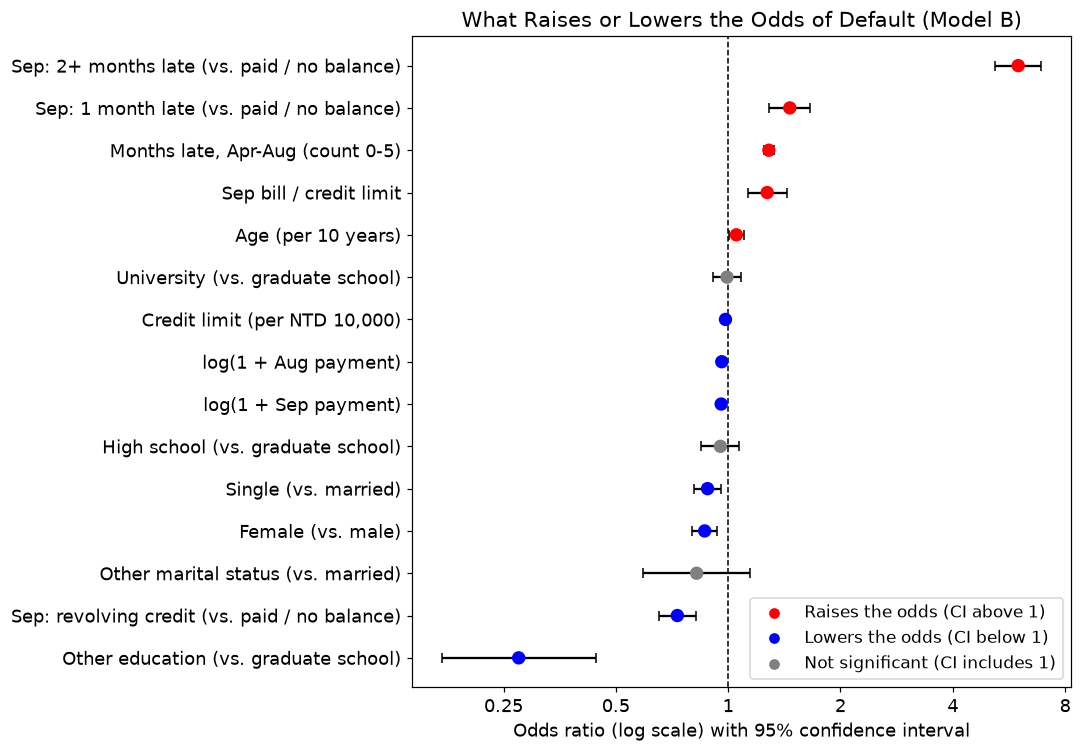

In [9]:
plot_df = odds.sort_values("odds_ratio")
colors = []
for low, high in zip(plot_df["ci_low"], plot_df["ci_high"]):
    if low > 1:
        colors.append("red")
    elif high < 1:
        colors.append("blue")
    else:
        colors.append("gray")

y_pos = np.arange(len(plot_df))
plt.figure(figsize=(10, 7))
plt.errorbar(plot_df["odds_ratio"], y_pos,
             xerr=[plot_df["odds_ratio"] - plot_df["ci_low"], plot_df["ci_high"] - plot_df["odds_ratio"]],
             fmt="none", ecolor="black", capsize=3)
plt.scatter(plot_df["odds_ratio"], y_pos, color=colors, s=60, zorder=3)
plt.axvline(1, color="black", linestyle="--", linewidth=1)
plt.xscale("log")
plt.xticks([0.25, 0.5, 1, 2, 4, 8], ["0.25", "0.5", "1", "2", "4", "8"])
plt.minorticks_off()
plt.yticks(y_pos, plot_df["feature"])
plt.scatter([], [], color="red", label="Raises the odds (CI above 1)")
plt.scatter([], [], color="blue", label="Lowers the odds (CI below 1)")
plt.scatter([], [], color="gray", label="Not significant (CI includes 1)")
plt.legend(loc="lower right")
plt.xlabel("Odds ratio (log scale) with 95% confidence interval")
plt.title("What Raises or Lowers the Odds of Default (Model B)")
plt.tight_layout()
plt.savefig(FIG_DIR / "odds_ratios.png", dpi=150)
plt.show()

**How to read this:** each dot is an odds ratio and the bar is its 95% CI. If the bar crosses the
dashed line at 1, we can't say that feature changes the odds.

What **raises** the odds of default (keeping everything else the same):

- **2+ months late in September** multiplies the odds by **5.99** (95% CI 5.19 to 6.91) compared with
  paying in full or having no balance. **1 month late** multiplies them by **1.46**.
- **Each earlier late month** (April–August) multiplies the odds by **1.29**. A client who was late in all
  five earlier months has about 1.29⁵ ≈ **3.50 times** the odds of a client who was never late.
- **Using more of the limit:** going from a 0% to a 100% balance-to-limit ratio multiplies the odds by **1.27**.

What **lowers** the odds:

- **Credit limit:** each extra NTD 10,000 lowers the odds by about 1.7% (OR 0.983). That sounds small, but
  NTD 100,000 more means 0.983¹⁰ ≈ **0.84**, about 16% lower odds. The bank probably gives bigger limits to
  clients it already trusts, so some of this is the bank's own screening.
- **Paying more:** paying 10 times more in September lowers the odds by about 9% (0.958 raised to
  ln 10 ≈ 2.30 is 0.91). August's payment has almost the same effect.
- **Revolving credit** (paid the minimum, not late) has lower odds than "paid / no balance" (OR **0.73**).
  This surprised us. We think it's because code -2 ("no balance") includes cards nobody is using, which
  may behave differently from cards in normal use.

**Demographics:**

- **Women** have about 13% lower odds than men (OR **0.87**), and **single** clients about 12% lower
  odds than married clients (OR **0.88**), after accounting for payment behavior.
- **Age** is just barely significant (OR 1.05 per 10 years, P = 0.03, CI 1.004 to 1.10).
- **University and high school** are not different from graduate school once payment behavior is in the
  model (P = 0.87 and 0.42).
- **"Other" education** has very low odds (OR 0.28). This small group (about 1.6% of clients) includes the
  undocumented codes 0, 5 and 6 that we merged, so we don't read much into it.

**Takeaway:** the three biggest effects are all about recent payment history, not about who the client is.

### 3d. Do we need sex, marital status and age?
Many lenders aren't allowed to use sex or marital status (and sometimes age) when they make credit
decisions. So we refit Model B without them and compare. (We only use the test set here to report how
much things change; it doesn't affect which model we pick.)

In [10]:
from sklearn.metrics import roc_auc_score

no_demo_cols = [c for c in X_train.columns if c not in ["FEMALE", "SINGLE", "MAR_OTHER", "AGE_10Y"]]
model_c = sm.Logit(y_train, sm.add_constant(X_train[no_demo_cols])).fit(disp=0)

auc_b = roc_auc_score(y_test, model_b.predict(sm.add_constant(X_test)))
auc_c = roc_auc_score(y_test, model_c.predict(sm.add_constant(X_test[no_demo_cols])))
print("Model B (all 15 features):        test AUC =", round(auc_b, 4), " AIC =", round(model_b.aic, 2))
print("Model C (no sex / marital / age): test AUC =", round(auc_c, 4), " AIC =", round(model_c.aic, 2))

Model B (all 15 features):        test AUC = 0.7637  AIC = 18133.15
Model C (no sex / marital / age): test AUC = 0.7636  AIC = 18163.53


Taking out sex, marital status and age changes the test AUC from **0.7637 to 0.7636**, basically
nothing. AIC goes up a little (18,133.15 → 18,163.53), so these columns carry a bit of information, but it
doesn't help rank clients at all. A lender could leave them out and lose nothing, which is better for
fairness and avoids legal problems.

## 4. Comparison models
We compare our logistic regression with:

- **Logistic regression on all 23 raw columns**, to check that our feature choices actually helped.
- **Decision tree** (max depth 5): one set of if/then rules.
- **Random forest:** 300 trees, each built on a random sample of the data, with their votes averaged.
- **Gradient boosting:** trees built one after another, each one fixing the mistakes of the ones before
  (the same idea as XGBoost from Module 5).

The tree models get the 23 raw columns. Trees can find their own cut points, so they don't need dummies
or logs.

We score every model with **5-fold cross-validation ROC-AUC** on the training set. The training set is
cut into 5 parts; each part takes a turn as a mini test set while the model trains on the other 4.
**ROC-AUC** is the chance that the model gives a random defaulter a higher score than a random
non-defaulter (0.5 = coin flip, 1 = perfect). It doesn't depend on a cutoff, which makes it a fair way to
compare models when only 22% of clients default. We show AUC with 3 decimals because the differences
between models are small.

### 4a. Picking the random forest's leaf size
`min_samples_leaf` is the smallest group of clients a tree is allowed to end on. Too small and the trees
memorize the training data; too big and they miss patterns. We try a few values.

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=500)
raw_cols = [c for c in df.columns if c != "DEFAULT"]
R_train = train[raw_cols]
R_test = test[raw_cols]

leaf_scores = {}
for leaf in [5, 10, 25, 50, 100]:
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, random_state=500, n_jobs=-1)
    scores = cross_val_score(rf, R_train, y_train, cv=cv, scoring="roc_auc")
    leaf_scores[leaf] = scores.mean()
    print("min_samples_leaf =", leaf, " CV AUC =", round(scores.mean(), 4))

best_leaf = max(leaf_scores, key=leaf_scores.get)
print("Best min_samples_leaf =", best_leaf)

min_samples_leaf = 5  CV AUC = 0.7804


min_samples_leaf = 10  CV AUC = 0.7843


min_samples_leaf = 25  CV AUC = 0.7869


min_samples_leaf = 50  CV AUC = 0.7869


min_samples_leaf = 100  CV AUC = 0.7868
Best min_samples_leaf = 50


Leaf sizes from 25 to 100 all give about the same CV AUC (**0.787**). Smaller leaves do worse (0.780 at
5) because the trees start memorizing the training clients. The code picks the highest one,
**min_samples_leaf = 50**, and we use it below.

### 4b. Cross-validation for all models

In [12]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

# name: (model, training features, test features)
models = {
    "Logistic regression (our features)": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), X_train, X_test),
    "Logistic regression (raw columns)": (make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)), R_train, R_test),
    "Decision tree": (DecisionTreeClassifier(max_depth=5, min_samples_leaf=50, random_state=500), R_train, R_test),
    "Random forest": (RandomForestClassifier(n_estimators=300, min_samples_leaf=best_leaf, random_state=500, n_jobs=-1), R_train, R_test),
    "Gradient boosting": (HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, random_state=500), R_train, R_test),
}

cv_mean = {}
cv_sd = {}
for name, (model, Xtr, Xte) in models.items():
    scores = cross_val_score(model, Xtr, y_train, cv=cv, scoring="roc_auc")
    cv_mean[name] = scores.mean()
    cv_sd[name] = scores.std()
    print(name)
    print("  CV AUC =", round(scores.mean(), 3), " SD across folds =", round(scores.std(), 3))

cv_results = pd.DataFrame({"cv_auc_mean": cv_mean, "cv_auc_sd": cv_sd}).sort_values("cv_auc_mean")
cv_results.round(3).to_csv(TABLE_DIR / "cv_results.csv")

Logistic regression (our features)
  CV AUC = 0.776  SD across folds = 0.012


Logistic regression (raw columns)
  CV AUC = 0.73  SD across folds = 0.013


Decision tree
  CV AUC = 0.758  SD across folds = 0.012


Random forest
  CV AUC = 0.787  SD across folds = 0.011


Gradient boosting
  CV AUC = 0.785  SD across folds = 0.011


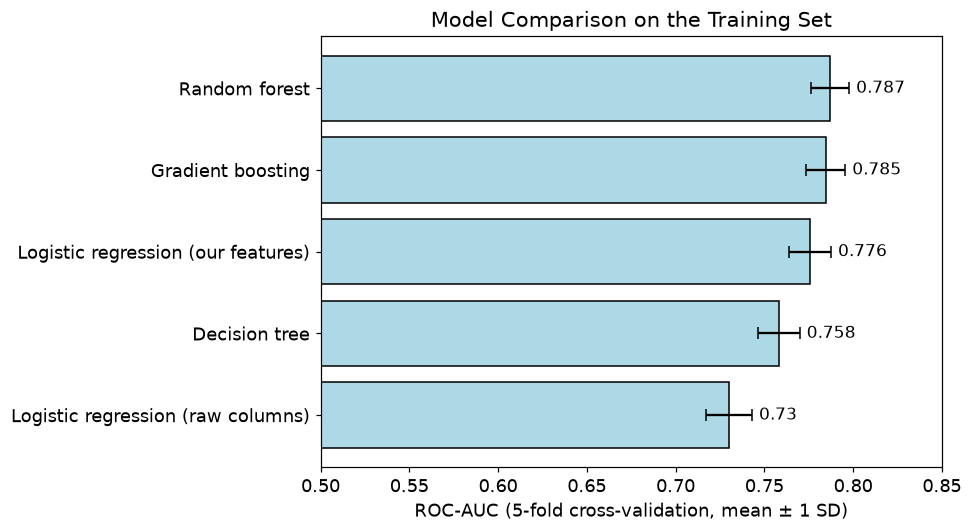

In [13]:
plt.figure(figsize=(9, 5))
plt.barh(cv_results.index, cv_results["cv_auc_mean"], xerr=cv_results["cv_auc_sd"],
         color="lightblue", edgecolor="black", capsize=4)
for i, (m, sd) in enumerate(cv_results.values):
    plt.text(m + sd + 0.004, i, str(round(m, 3)), va="center", fontsize=11)
plt.xlim(0.5, 0.85)
plt.xlabel("ROC-AUC (5-fold cross-validation, mean ± 1 SD)")
plt.title("Model Comparison on the Training Set")
plt.tight_layout()
plt.savefig(FIG_DIR / "cv_model_comparison.png", dpi=150)
plt.show()

- The **random forest** scored highest (**0.787**), with **gradient boosting** right behind (**0.785**).
- Our **logistic regression scored 0.776**, about **0.011 lower** than the random forest. The SD across
  folds is about 0.01, so the gap is about one SD: real, but small.
- The **logistic regression on raw columns** scored only **0.730**. Same method, but without our feature
  work it lost about 0.046. So grouping the repayment codes and fixing the skewed amounts helped **more**
  than switching to a more complex model.
- One **decision tree** (0.758) did worse than both tree ensembles, which is what we expected.

We take the **logistic regression (our features)** and the **random forest** into notebook 04.

## 5. Save predictions for notebook 04
- **Out-of-fold predictions on the training set:** every training client gets a probability from a model
  that didn't see them during training. Notebook 04 uses these to choose a cutoff, so the test set stays
  untouched until the very end.
- **Test-set predictions:** each model is trained on the full training set and then scores the test set.

In [14]:
from sklearn.model_selection import cross_val_predict

oof = pd.DataFrame({"y": y_train.values})
for name in ["Logistic regression (our features)", "Random forest"]:
    model, Xtr, Xte = models[name]
    oof[name] = cross_val_predict(model, Xtr, y_train, cv=cv, method="predict_proba")[:, 1]
oof.to_csv(PROCESSED_DIR / "train_oof_predictions.csv", index=False)

test_pred = pd.DataFrame({"y": y_test.values})
for name, (model, Xtr, Xte) in models.items():
    model.fit(Xtr, y_train)
    test_pred[name] = model.predict_proba(Xte)[:, 1]
test_pred.to_csv(PROCESSED_DIR / "test_predictions.csv", index=False)

print("Saved", len(oof), "out-of-fold predictions and", len(test_pred), "test predictions")

Saved 20975 out-of-fold predictions and 8990 test predictions


## 6. What does the random forest pay attention to?
A random forest doesn't have odds ratios. Instead, it can tell us how much each column helped its trees
split the clients into "default" and "no default" groups (the importance values add up to 1).

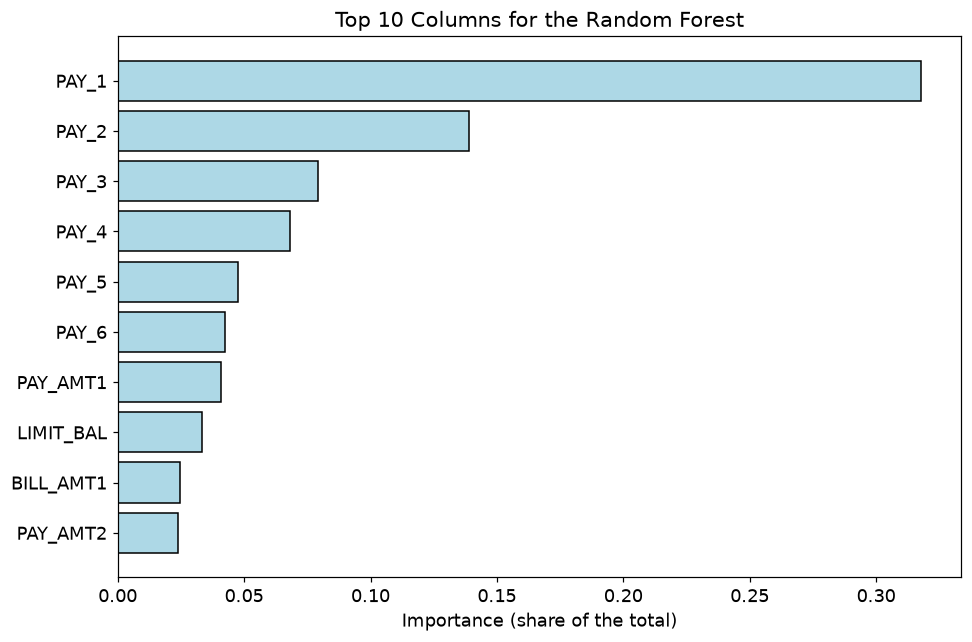

PAY_1        0.318
PAY_2        0.139
PAY_3        0.079
PAY_4        0.068
PAY_5        0.048
PAY_6        0.042
PAY_AMT1     0.041
LIMIT_BAL    0.033
BILL_AMT1    0.025
PAY_AMT2     0.024


In [15]:
rf_model = models["Random forest"][0]
importance = pd.Series(rf_model.feature_importances_, index=raw_cols).sort_values()
top = importance.tail(10)

plt.figure(figsize=(9, 6))
plt.barh(top.index, top.values, color="lightblue", edgecolor="black")
plt.xlabel("Importance (share of the total)")
plt.title("Top 10 Columns for the Random Forest")
plt.tight_layout()
plt.savefig(FIG_DIR / "rf_feature_importance.png", dpi=150)
plt.show()

print(importance.sort_values(ascending=False).head(10).round(3).to_string())

The random forest pays attention to the same things as the logistic regression. **September repayment
status (PAY_1)** is by far the most important column (**0.32**), followed by the other five months of
repayment status, then September's payment, the credit limit and the bill. Sex, education, marital status
and age don't make the top 10. Two very different models agreeing on what matters makes us more confident
in this finding.